In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy import stats
import os

In [2]:
df = pd.read_csv('../data/regime_change/bm_n2525_GenBIN_Fr1.000_mpri12.300_spri0.340_msec0.000_ssec0.000_WarmA2.000_c200_w_200.csv')
df.head(10)

,x
0,14.681582
1,14.728345
2,14.128259
3,13.978904
4,14.607772
5,14.630061
6,14.248487
7,14.437816
8,14.291825
9,14.711693


In [3]:
df.shape

(2525, 1)

In [4]:
df.describe

<bound method NDFrame.describe of               x
0     14.681582
1     14.728345
2     14.128259
3     13.978904
4     14.607772
...         ...
2520  12.369776
2521  12.614107
2522  12.346703
2523  12.599649
2524  12.536524

[2525 rows x 1 columns]>

In [5]:
df.info

<bound method DataFrame.info of               x
0     14.681582
1     14.728345
2     14.128259
3     13.978904
4     14.607772
...         ...
2520  12.369776
2521  12.614107
2522  12.346703
2523  12.599649
2524  12.536524

[2525 rows x 1 columns]>

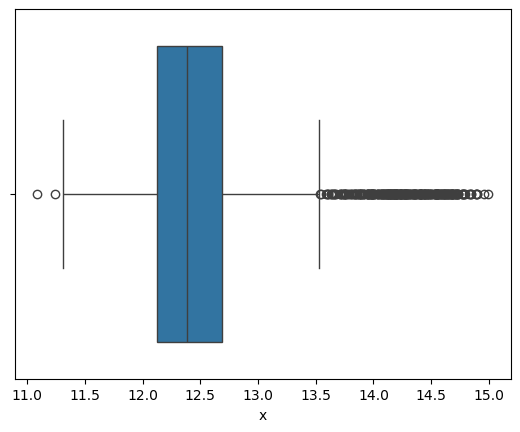

In [6]:
for i in df.select_dtypes(include="number").columns:
    sns.boxplot(data=df, x=i)
    plt.show

In [7]:
scale = StandardScaler()
df_scaled = pd.DataFrame(scale.fit_transform(df), columns=df.columns, index=df.index)
df_scaled

,x
0,3.029613
1,3.096013
2,2.243926
3,2.031851
4,2.924806
...,...
2520,-0.253019
2521,0.093917
2522,-0.285782
2523,0.073388


In [8]:
df.isna().sum()
df.isna().mean() * 100

x    0.0
dtype: float64

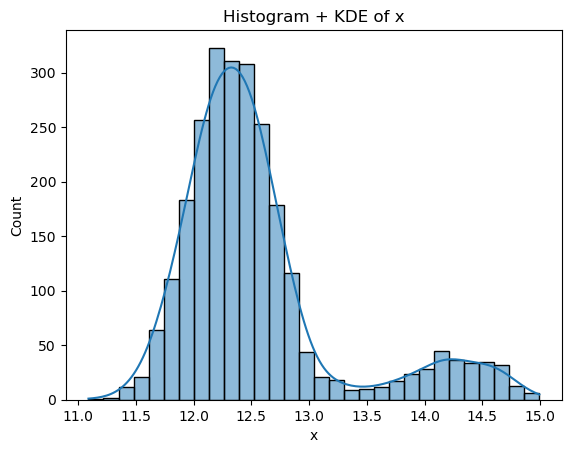

In [9]:
col = df.columns[0]

sns.histplot(df[col], kde=True, bins=30)
plt.title("Histogram + KDE of " + col)
plt.show()

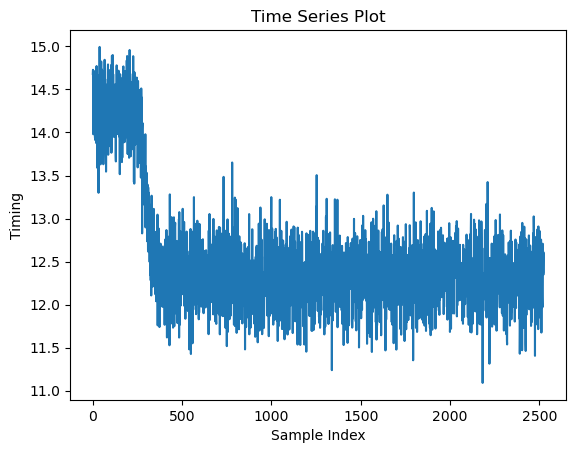

In [10]:
col = df.columns[0]

plt.plot(df[col])
plt.title("Time Series Plot")
plt.xlabel("Sample Index")
plt.ylabel("Timing")
plt.show()

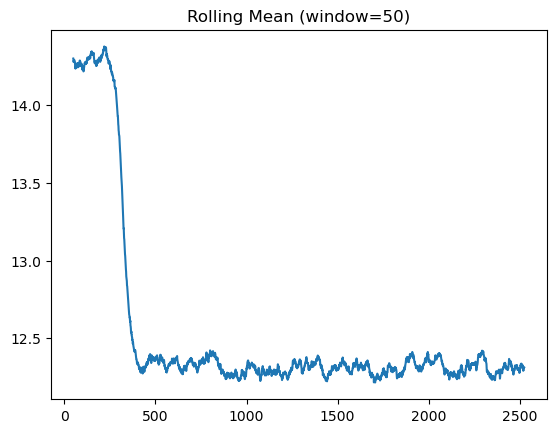

In [11]:
df['roll_mean_50'] = df[col].rolling(window=50).mean()
plt.plot(df['roll_mean_50'])
plt.title("Rolling Mean (window=50)")
plt.show()

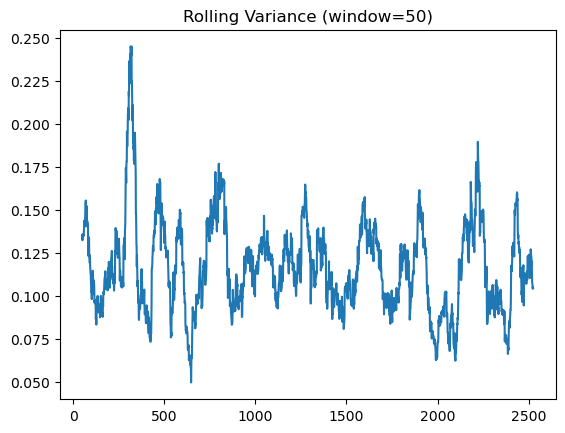

In [12]:
df['rollingVariance'] = df[col].rolling(window=50).var()
plt.plot(df['rollingVariance'])
plt.title("Rolling Variance (window=50)")
plt.show()

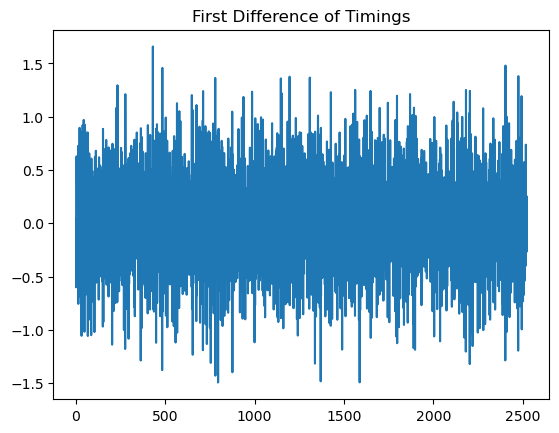

In [13]:
df['diff'] = df[col].diff()
plt.plot(df['diff'])
plt.title("First Difference of Timings")
plt.show()

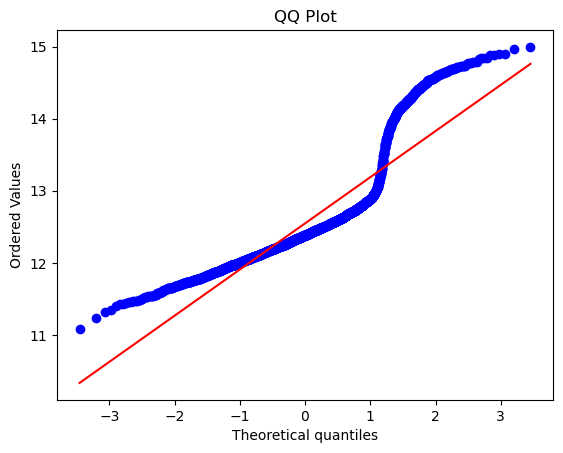

In [14]:
stats.probplot(df[col], dist="norm", plot=plt)
plt.title("QQ Plot")
plt.show()

In [15]:
df[col].skew(), df[col].kurt()

(np.float64(1.5943267611302492), np.float64(2.1446961508441826))

In [16]:
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outliers = df[(df[col] < lower) | (df[col] > upper)]
outliers.head(), len(outliers)

(           x  roll_mean_50  rollingVariance      diff
 0  14.681582           NaN              NaN       NaN
 1  14.728345           NaN              NaN  0.046763
 2  14.128259           NaN              NaN -0.600086
 3  13.978904           NaN              NaN -0.149354
 4  14.607772           NaN              NaN  0.628867,
 286)